## Business Problem & Project Overview

In an era of increasing data privacy regulations (such as GDPR and CCPA), organizations handling large-scale automotive video and image data face the critical challenge of protecting Personally Identifiable Information (PII). License plates are primary identifiers that must be anonymized before data can be used for public datasets, AI training, or insurance processing. This project implements an automated, high-speed solution to detect license plates in diverse environments and apply a gaussian blur to ensure privacy compliance while maintaining the utility of the surrounding visual data.

### Install Dependencies

In [ ]:
!pip install --quiet torch torchvision ultralytics opencv-python matplotlib pillow requests pandas seaborn

In [1]:
%matplotlib inline
import os

import time
from pathlib import Path

import numpy as np
import requests
import torch
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import seaborn as sns
import random # Ensure random is imported for seeding

SEED = 39 # Seed for random number generators
random.seed(SEED) # Set seed for Python's random module
np.random.seed(SEED) # Set seed for NumPy's random module

np.set_printoptions(suppress=True, precision=4, linewidth=200)
torch.set_printoptions(sci_mode=False, precision=4)

print(f"PyTorch     : {torch.__version__}")
print(f"CUDA        : {torch.cuda.is_available()}")


PyTorch     : 2.11.0+cu130
CUDA        : True


In [2]:
torch.device("cuda")

device(type='cuda')

### Data Audit & Exploration

**Images**:

The dataset is organized into three main subsets:

**Train**: This subset contains an expansive collection of 25,470 images meticulously curated for training purposes.

**Validation (Val)**: With 1,000 images, the "val" subset enables thorough model performance evaluation during development.

**Test**: The "test" subset comprises 400 images specifically reserved for post-training model evaluation.

In [3]:
# Path to the dataset folder on the vast.ai instance
# Upload your dataset here (see Step 5 in the setup guide)
shared_folder_path = "./data"

#### Display some random images from "test", "train", and "val" folders and inspect them visually.

In [4]:
import random

def get_random_images(directory, num_images):
    """Returns a list of random image file paths from the given directory."""
    all_images = [os.path.join(directory, f) for f in os.listdir(directory) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp'))]
    return random.sample(all_images, min(num_images, len(all_images)))

def display_images(image_paths, title="Random Images", ncols=5):
    """Displays a grid of images."""
    if not image_paths:
        print(f"No images to display for: {title}")
        return

    nrows = (len(image_paths) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = axes.flatten()

    fig.suptitle(title, fontsize=16)

    for i, img_path in enumerate(image_paths):
        try:
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].set_title(os.path.basename(img_path), fontsize=8)
            axes[i].axis('off')
        except Exception as e:
            print(f"Could not load image {img_path}: {e}")
            axes[i].axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
    plt.show()

### Displaying Random Images

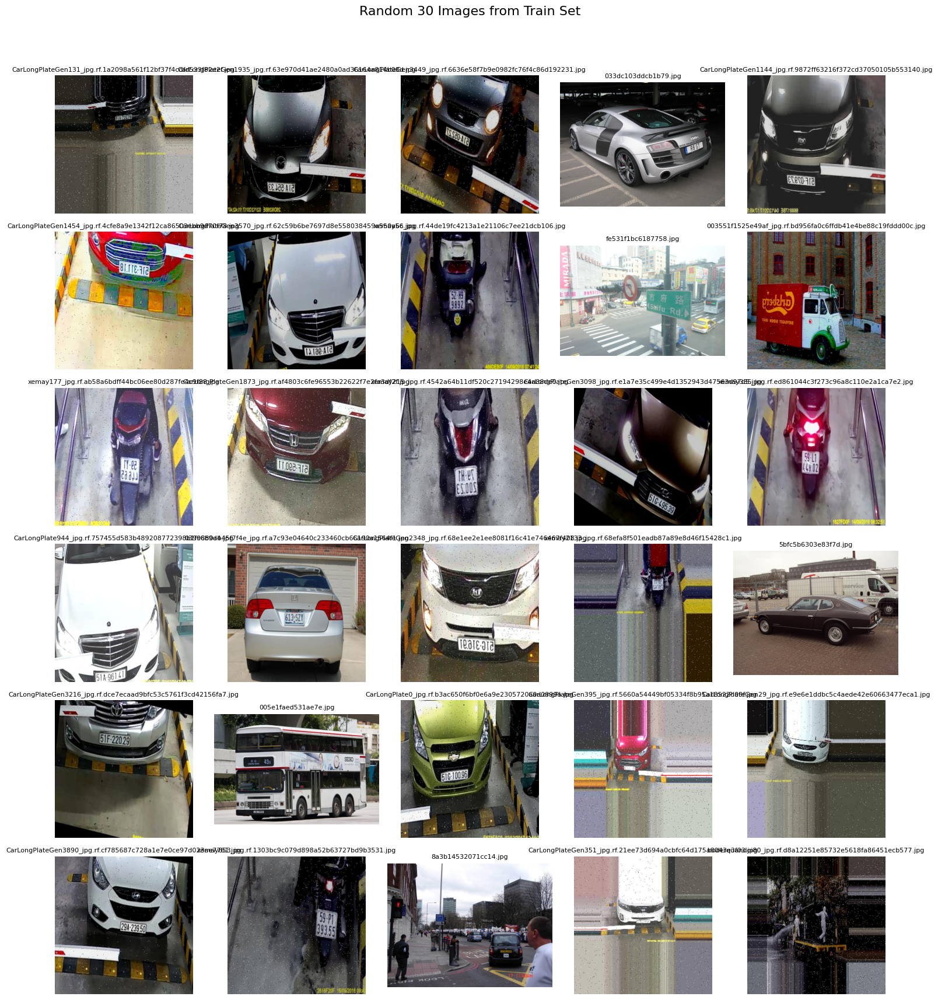

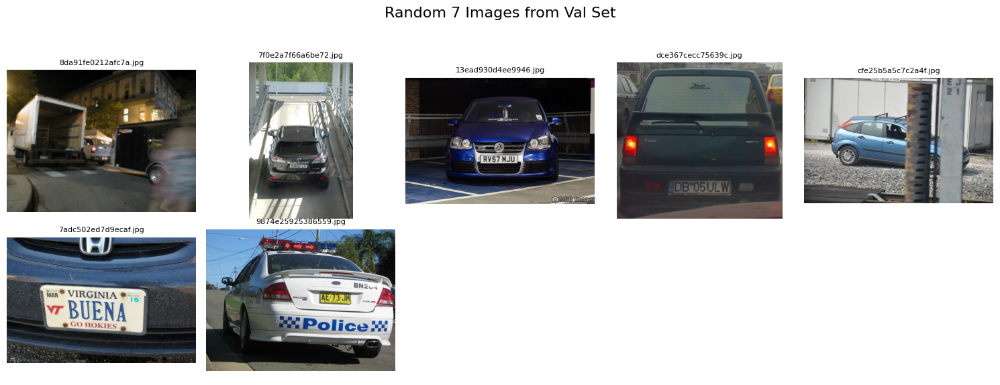

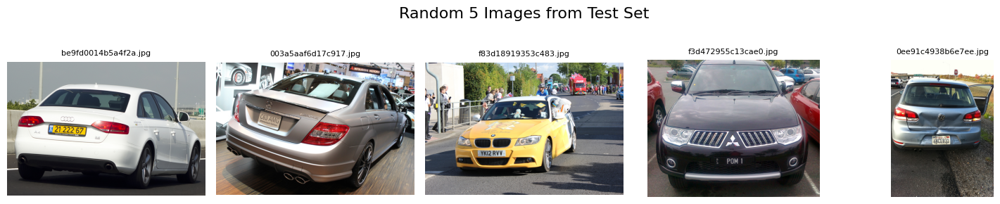

In [5]:
# Define image directories
images_base_path = os.path.join(shared_folder_path, 'images')
train_images_dir = os.path.join(images_base_path, 'train')
val_images_dir = os.path.join(images_base_path, 'val')
test_images_dir = os.path.join(images_base_path, 'test')

# Number of images to display from each set
num_train_to_display = 30
num_val_to_display = 7
num_test_to_display = 5

# Get random image paths
random_train_images = get_random_images(train_images_dir, num_train_to_display)
random_val_images = get_random_images(val_images_dir, num_val_to_display)
random_test_images = get_random_images(test_images_dir, num_test_to_display)

# Display images
display_images(random_train_images, title=f"Random {num_train_to_display} Images from Train Set")
display_images(random_val_images, title=f"Random {num_val_to_display} Images from Val Set")
display_images(random_test_images, title=f"Random {num_test_to_display} Images from Test Set")

**Labels**:

Corresponding to the image subsets, the "labels" directory holds YOLO annotation files in "train," "val," and "test" subdirectories. These annotation files provide precise information about license plate locations within the images, including class labels, bounding box coordinates, and object confidence scores.

Use the annotation files in "labels" directory to overlay bounding boxes onto raw images.

Each .txt file has one line per object:

```bash
<class_id> <x_center> <y_center> <width> <height>
```

**All values are normalized (0–1) relative to image dimensions.**

Display some random images to visually check the accuracy of the bounding boxes.

In [6]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

def parse_yolo_annotation(label_path, img_width, img_height):
    """Parses a YOLO annotation file and returns bounding boxes in pixel coordinates."""
    boxes = []
    if not os.path.exists(label_path):
        return boxes

    with open(label_path, 'r') as f:
        for line in f:
            parts = list(map(float, line.strip().split()))
            class_id = int(parts[0])
            center_x, center_y, width, height = parts[1:]

            x_center = center_x * img_width
            y_center = center_y * img_height
            box_width = width * img_width
            box_height = height * img_height

            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            boxes.append({'class_id': class_id, 'bbox': [x1, y1, x2, y2]})
    return boxes

def display_images_with_boxes(image_paths, label_base_path, title="Images with Bounding Boxes", ncols=5):
    """Displays a grid of images with overlaid bounding boxes using OpenCV."""
    if not image_paths:
        print(f"No images to display for: {title}")
        return

    nrows = (len(image_paths) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = axes.flatten()

    fig.suptitle(title, fontsize=16)

    for i, img_path in enumerate(image_paths):
        try:
            img_pil = Image.open(img_path)
            # Ensure image is RGB for consistent OpenCV drawing
            img_pil = img_pil.convert('RGB')
            img_np = np.array(img_pil).copy()
            img_width, img_height = img_pil.size

            img_basename = os.path.basename(img_path)
            img_name_without_ext = os.path.splitext(img_basename)[0]
            label_filename = img_name_without_ext + '.txt'
            label_path = os.path.join(label_base_path, label_filename)

            boxes = parse_yolo_annotation(label_path, img_width, img_height)

            for box_data in boxes:
                x1, y1, x2, y2 = box_data['bbox']
                # Ensure coordinates are within image bounds before drawing
                x1 = max(0, x1)
                y1 = max(0, y1)
                x2 = min(img_width - 1, x2)
                y2 = min(img_height - 1, y2)

                if x2 > x1 and y2 > y1: # Only draw if box is valid
                    cv2.rectangle(img_np, (x1, y1), (x2, y2), (255, 0, 0), 5)

            ax = axes[i]
            ax.imshow(img_np)
            ax.set_title(os.path.basename(img_path), fontsize=8)
            ax.axis('off')

        except Exception as e:
            print(f"Could not process image {img_path} or its labels: {e}")
            axes[i].axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

### Displaying Random Images with Bounding Boxes

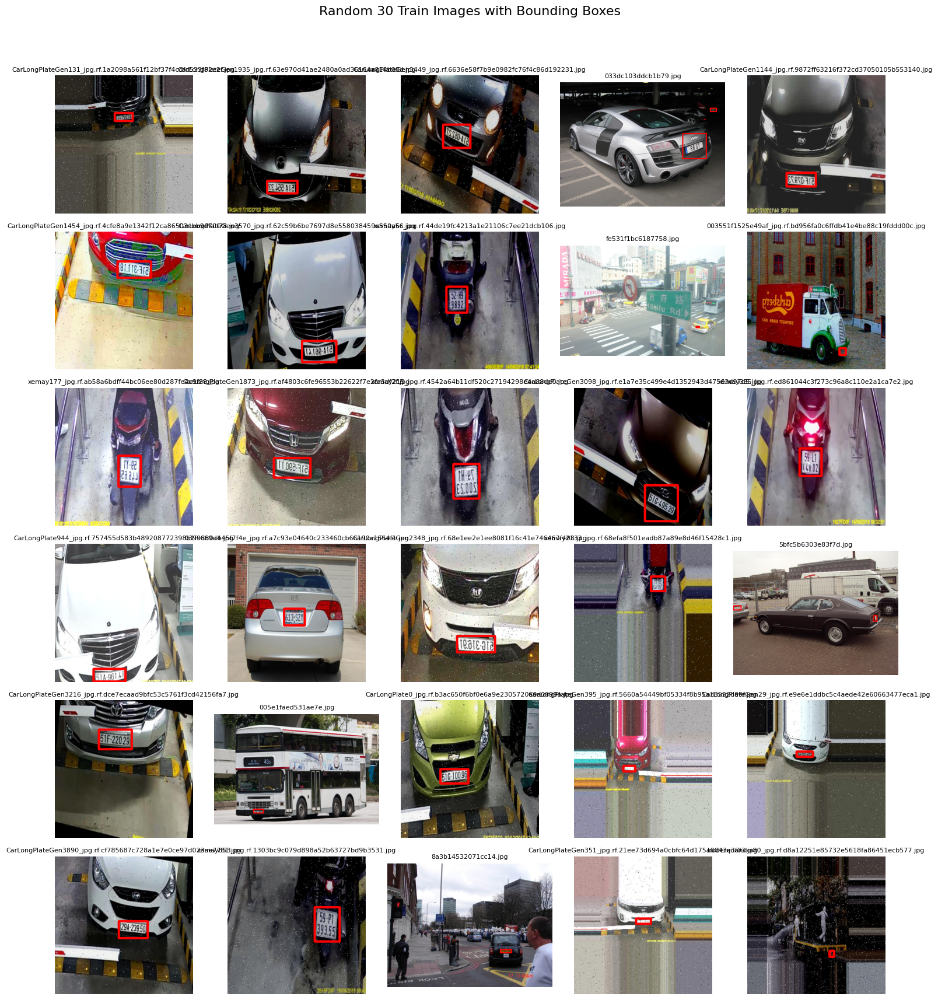

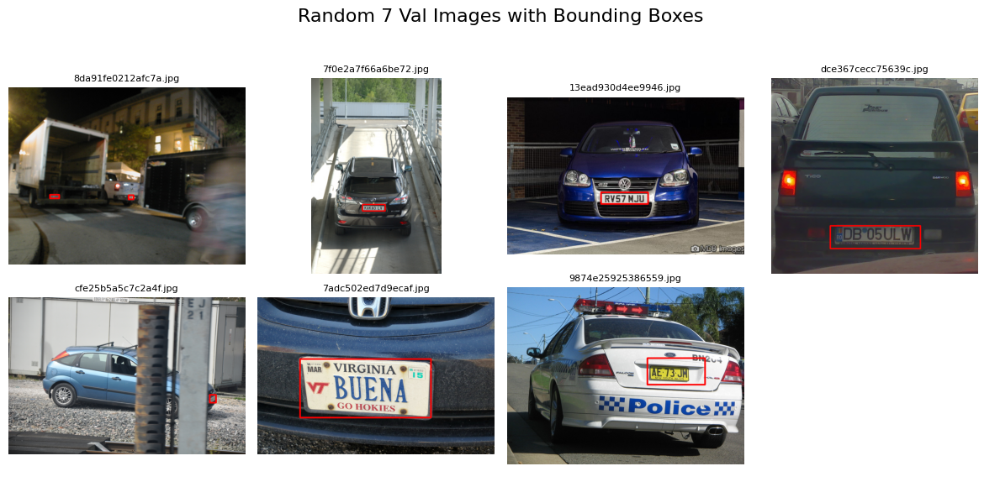

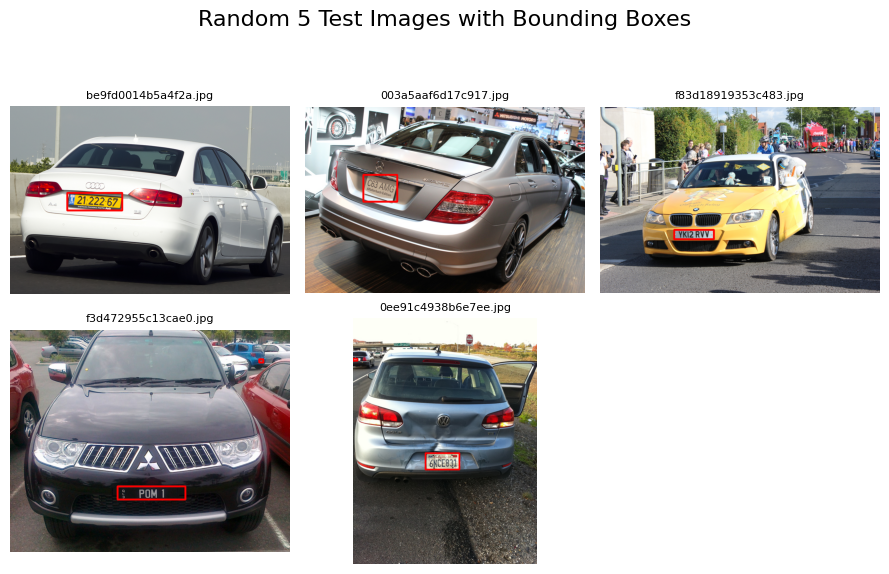

In [7]:
# Define label directories
labels_base_path = os.path.join(shared_folder_path, 'labels')
train_labels_dir = os.path.join(labels_base_path, 'train')
val_labels_dir = os.path.join(labels_base_path, 'val')
test_labels_dir = os.path.join(labels_base_path, 'test')

# Display images with bounding boxes
display_images_with_boxes(random_train_images, train_labels_dir, title=f"Random {num_train_to_display} Train Images with Bounding Boxes", ncols=5)
display_images_with_boxes(random_val_images, val_labels_dir, title=f"Random {num_val_to_display} Val Images with Bounding Boxes", ncols=4)
display_images_with_boxes(random_test_images, test_labels_dir, title=f"Random {num_test_to_display} Test Images with Bounding Boxes", ncols=3)

**Based on the visual inspection of the bounding boxes in the above images, it looks quality of annotation is quite good / accurate.**

Accuracy of bounding boxes in the annotations is crucial as our object detection model will be trained using this data. Inaccurate training data results in poor learning (i.e., bounding boxes predicted by the model will also be inaccurate).

### Load and train YOLOv8 model

We utilize the YOLOv8 model, which processes images in a single pass (and hence much faster than a two-stage detector), making it suitable for real-time edge deployment on traffic cameras or mobile devices.

#### Key Features of YOLOv8

- Advanced Backbone and Neck Architectures: YOLOv8 employs state-of-the-art backbone and neck architectures, resulting in improved feature extraction and object detection performance.
  
- Anchor-free Split Ultralytics Head: YOLOv8 adopts an anchor-free split Ultralytics head, which contributes to better accuracy and a more efficient detection process compared to anchor-based approaches.

- Optimized Accuracy-Speed Tradeoff: With a focus on maintaining an optimal balance between accuracy and speed, YOLOv8 is suitable for real-time object detection tasks in diverse application areas.

- Variety of Pretrained Models: YOLOv8 offers a range of pretrained models to cater to various tasks and performance requirements, making it easier to find the right model for your specific use case.

We have a massive dataset comprising of 25,470 training images covering a vast and diverse range of plate formats, lighting conditions, and camera angles, some of which are very challenging.

So we selected the 'yolov8m' model, striking a balance between speed and performance.

See the performance of various YOLOv8 detection models on the COCO dataset.

<Insert of the performance table from Ultralytics website>

The internal data loader in the Ultralytics framework automatically pre-processes raw images.

    - Pixel Scaling: It automatically converts pixel values from the standard [0, 255] range to [0.0, 1.0].

    - Resizing: It resizes your images to the specified input size (default is 640x640) while maintaining aspect ratio and adding padding if necessary.

    - Augmentations: It applies complex augmentations (like Mosaic, MixUp, flipping, and color adjustments) on the fly, depending on the training configuration. We are not using this feature.

In [8]:
from ultralytics import YOLO
import yaml
import os # Ensure os is imported

# Define the path to the shared folder from the previous cells

# Create data.yaml content
data_yaml_content = f"""
train: {shared_folder_path}/images/train
val: {shared_folder_path}/images/val
test: {shared_folder_path}/images/test

nc: 1  # number of classes (just 'license_plate')
names: ['license_plate']  # class names
"""

# Define the path to save data.yaml in a writable location (e.g., current directory)
data_yaml_path = './data.yaml'

# Write data.yaml file
with open(data_yaml_path, 'w') as f:
    f.write(data_yaml_content)

print(f"data.yaml created at: {data_yaml_path}")

# Define the project directory for saving runs
project_dir = './runs/yolov8_training_runs'

# 1. Define the path to your last checkpoint
checkpoint_path = '/workspace/runs/detect/runs/yolov8_training_runs/yolov8m_license_plate_detection/weights/last.pt'

# 2. Check if the checkpoint exists to resume, otherwise start fresh
if os.path.exists(checkpoint_path):
    print(f"Found checkpoint at {checkpoint_path}. Resuming training...")
    # Load the specific checkpoint, not the base yolov8m.pt
    model = YOLO(checkpoint_path)
    # Resume training - you don't need to pass data, epochs, or imgsz again!
    results = model.train(resume=True, amp=False, lr0=0.005, patience=5)
else:
    print("No checkpoint found. Starting training from scratch...")
    
    model = YOLO('yolov8m.pt')
    results = model.train(data=data_yaml_path, epochs=100, imgsz=640,
                          name='yolov8m_license_plate_detection',
                          project=project_dir, save_period=10)

print("Model training complete!")

data.yaml created at: ./data.yaml
Found checkpoint at /workspace/runs/detect/runs/yolov8_training_runs/yolov8m_license_plate_detection/weights/last.pt. Resuming training...
New https://pypi.org/project/ultralytics/8.4.56 available 😃 Update with 'pip install -U ultralytics'
WARNING ⚠️ model '/workspace/runs/detect/runs/yolov8_training_runs/yolov8m_license_plate_detection/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.55 🚀 Python-3.12.13 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24124MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=None, dfl

### Run Inference with Best Weights

After training, the best performing weights are saved as `best.pt`. We can load these weights and use the trained model to run inference on new images, such as those in the 'test' set, to see its performance.

In [9]:
# Define the path to the directory where training runs are saved
project_dir = '/workspace/runs/detect/runs/yolov8_training_runs'

# The specific run name you used during training
run_name = 'yolov8m_license_plate_detection'

# Construct the path to the 'best.pt' weights for this run
best_model_path = os.path.join(project_dir, run_name, 'weights', 'best.pt')

print(f"Attempting to load best model from: {best_model_path}")

# Load the best trained model
try:
    inference_model = YOLO(best_model_path)
    print("Successfully loaded the best model for inference.")
except Exception as e:
    print(f"Error loading model: {e}")
    print("Please ensure the training run completed and 'best.pt' exists at the specified path.")
    inference_model = None # Set to None to prevent further errors if loading fails


Attempting to load best model from: /workspace/runs/detect/runs/yolov8_training_runs/yolov8m_license_plate_detection/weights/best.pt
Successfully loaded the best model for inference.


In [10]:
if inference_model:
    # Define the path to the test images (assuming similar structure as before)
    images_base_path = os.path.join(shared_folder_path, 'images')
    test_images_dir = os.path.join(images_base_path, 'test')

    # Get a list of test image paths
    test_image_files = [os.path.join(test_images_dir, f) for f in os.listdir(test_images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not test_image_files:
        print("No test images found to run inference on.")
    else:
        # Limit to a few for demonstration if there are many
        num_inference_images = min(30, len(test_image_files)) 
        selected_test_images = random.sample(test_image_files, num_inference_images)

        print(f"Running inference on {num_inference_images} random test images for latency calculation...")

        # Measure inference latency
        start_time = time.time()
        results_latency = inference_model.predict(source=selected_test_images, save=False, save_txt=False, save_conf=False, conf=0.25)
        end_time = time.time()

        # Total time for the batch
        total_inference_time = end_time - start_time
        # Average latency per image
        average_latency_per_image = total_inference_time / num_inference_images

        print(f"\nInference Latency (average per image): {average_latency_per_image:.4f} seconds")

        print("\nRunning inference on the same set of images, saving results for display and blurring.")
        # Run inference again, this time saving results for subsequent display and blurring
        results = inference_model.predict(source=selected_test_images, save=True, save_txt=True, save_conf=True, conf=0.25)

        print("Inference complete. Results, including images with detections and labels, are saved.")
        print("You can find the output images in the 'runs/detect/predictX' directory (where X is an incrementing number).")
else:
    print("Inference model not loaded. Cannot calculate latency or run inference.")


Running inference on 30 random test images for latency calculation...

0: 640x640 1 license_plate, 7.8ms
1: 640x640 3 license_plates, 7.8ms
2: 640x640 2 license_plates, 7.8ms
3: 640x640 1 license_plate, 7.8ms
4: 640x640 1 license_plate, 7.8ms
5: 640x640 1 license_plate, 7.8ms
6: 640x640 1 license_plate, 7.8ms
7: 640x640 1 license_plate, 7.8ms
8: 640x640 1 license_plate, 7.8ms
9: 640x640 2 license_plates, 7.8ms
10: 640x640 1 license_plate, 7.8ms
11: 640x640 3 license_plates, 7.8ms
12: 640x640 1 license_plate, 7.8ms
13: 640x640 1 license_plate, 7.8ms
14: 640x640 2 license_plates, 7.8ms
15: 640x640 1 license_plate, 7.8ms
16: 640x640 1 license_plate, 7.8ms
17: 640x640 1 license_plate, 7.8ms
18: 640x640 2 license_plates, 7.8ms
19: 640x640 1 license_plate, 7.8ms
20: 640x640 1 license_plate, 7.8ms
21: 640x640 2 license_plates, 7.8ms
22: 640x640 4 license_plates, 7.8ms
23: 640x640 2 license_plates, 7.8ms
24: 640x640 1 license_plate, 7.8ms
25: 640x640 1 license_plate, 7.8ms
26: 640x640 1 licens

### Display Inference Results with Bounding Boxes

Displaying results from: /workspace/runs/detect/predict-2


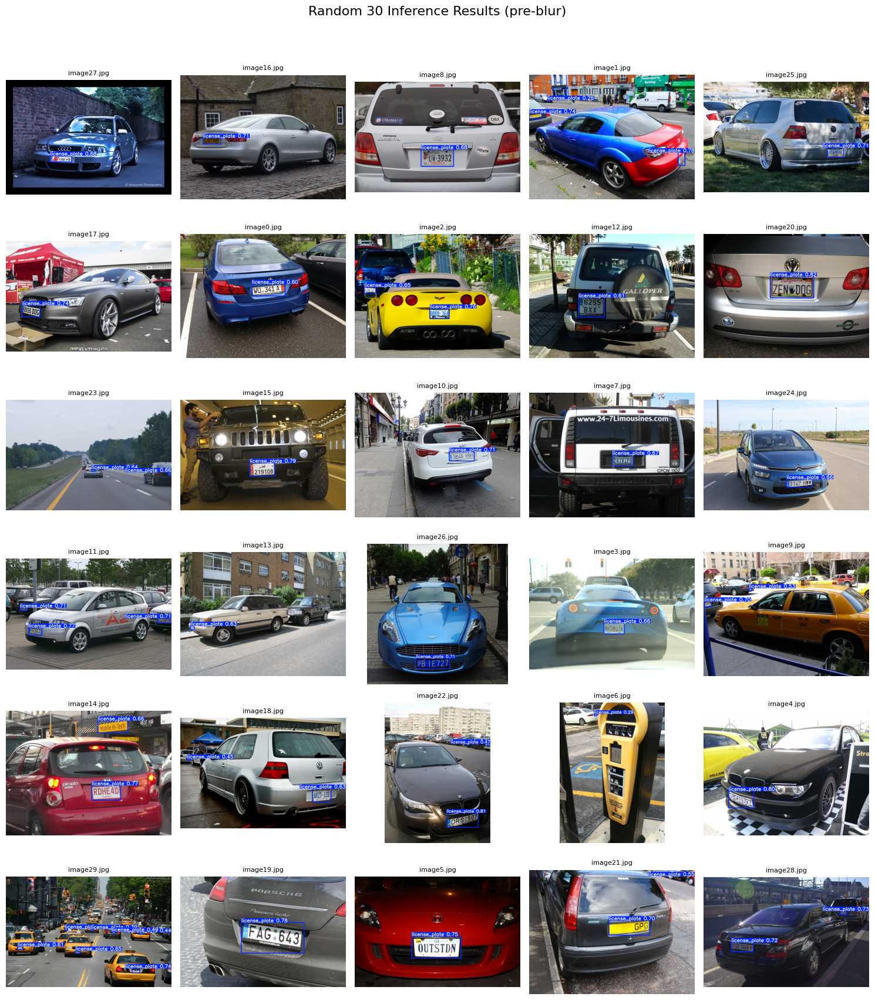

In [11]:
if inference_model and 'results' in locals() and results:
    # Ultralytics saves prediction results to a 'runs/detect/predict' folder.
    # We need to find the latest predict folder.
    predict_runs_base = os.path.join(os.getcwd(), 'runs', 'detect')
    predict_folders = [d for d in os.listdir(predict_runs_base) if os.path.isdir(os.path.join(predict_runs_base, d)) and d.startswith('predict')]
    predict_folders.sort(key=lambda x: int(''.join(filter(str.isdigit, x))) if any(char.isdigit() for char in x) else 0, reverse=True)

    if predict_folders:
        latest_predict_folder = os.path.join(predict_runs_base, predict_folders[0])
        print(f"Displaying results from: {latest_predict_folder}")

        # The images with bounding boxes are saved directly in this folder
        # and the corresponding labels (if save_txt=True) in a 'labels' subfolder.
        detected_image_paths = [os.path.join(latest_predict_folder, f) for f in os.listdir(latest_predict_folder)
                                if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        detected_label_paths = os.path.join(latest_predict_folder, 'labels')

        if detected_image_paths:
            display_num = min(30, len(detected_image_paths))
            random_detected_images = random.sample(detected_image_paths, display_num)

            # We use display_images_with_boxes, but since these are the *output* of inference,
            # the bounding boxes are already drawn on them. We pass an empty label_base_path
            # or a path that won't find .txt files to avoid trying to re-draw.
            # Alternatively, we could just use display_images, but display_images_with_boxes
            # is more robust for general image display.
            display_images(random_detected_images, title=f"Random {display_num} Inference Results (pre-blur)", ncols=5)
        else:
            print("No detected images found in the latest predict folder.")
    else:
        print("No 'predict' folders found in 'runs/detect'. Inference might not have run.")
else:
    print("Inference model not loaded or results not available. Cannot display.")

### Model Evaluation: mAP@50-95

In [12]:
# The data.yaml path was defined earlier, make sure it's accessible
# data_yaml_path = './data.yaml'

if inference_model and os.path.exists(data_yaml_path):
    print("Evaluating model on the test set to calculate mAP@50-95...")
    # Run model.val() on the test split to get mAP and other metrics
    metrics = inference_model.val(data=data_yaml_path, split='test')

    # Extract and display mAP@50-95
    map_50_95 = metrics.results_dict['metrics/mAP50-95(B)']
    print(f"\nmAP@50-95 on Test Set: {map_50_95:.4f}")
else:
    print("Inference model not loaded or data.yaml not found. Cannot calculate mAP.")


Evaluating model on the test set to calculate mAP@50-95...
Ultralytics 8.4.55 🚀 Python-3.12.13 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24124MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3851.1±1186.6 MB/s, size: 266.6 KB)
val: Scanning /workspace/data/labels/test.cache... 386 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 386/386 161.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 5.9it/s 4.3s0.2s
                   all        386        512      0.916      0.898      0.919      0.672
Speed: 0.8ms preprocess, 7.2ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /workspace/runs/detect/val-2

mAP@50-95 on Test Set: 0.6723


### Blur Detected Objects

Now, let's take the results from our inference and apply a Gaussian blur to the regions where license plates were detected. The blurred images will be saved in a new 'blurred' subfolder for review.

In [13]:
if inference_model and 'results' in locals() and results:
    # Define the output directory for blurred images
    blurred_output_dir = os.path.join(images_base_path, 'blurred_gaussian')
    os.makedirs(blurred_output_dir, exist_ok=True)

    print(f"Saving blurred images to: {blurred_output_dir}")

    # List to store Laplacian variances of blurred regions
    all_laplacian_variances = []

    inference_images_path = '/workspace/runs/detect/predict/'

    # Iterate through each image's results
    for res in results:
        img_path = os.path.join(inference_images_path, res.path)
        img_name = os.path.basename(img_path)

        # Load the original image using OpenCV
        # Convert to RGB if needed, as YOLOv8's results might be in BGR (OpenCV default)
        img = cv2.imread(img_path)
        if img is None:
            print(f"Could not load image {img_path}. Skipping blurring.")
            continue

        # Create a copy to draw on, so the original isn't modified
        blurred_img = img.copy()

        # Iterate through each detected bounding box
        # res.boxes contains normalized coordinates, so we need to convert them to pixel values
        for *xyxy, conf, cls in res.boxes.data.cpu().numpy():
            # Convert normalized xyxy (x1, y1, x2, y2) to integer pixel coordinates
            x1, y1, x2, y2 = map(int, xyxy)

            # Extract the region of interest (ROI) for blurring
            # Ensure coordinates are within image boundaries
            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(blurred_img.shape[1], x2)
            y2 = min(blurred_img.shape[0], y2)

            if x2 > x1 and y2 > y1: # Check if the bounding box is valid
                roi = blurred_img[y1:y2, x1:x2]

                # Apply Gaussian blur to the ROI
                # Kernel size (e.g., 25x25) and standard deviation (sigmaX=0) can be adjusted
                blurred_roi = cv2.GaussianBlur(roi, (25, 25), 0)

                # Calculate Laplacian Variance for the blurred ROI
                # Convert to grayscale first for Laplacian calculation
                gray_blurred_roi = cv2.cvtColor(blurred_roi, cv2.COLOR_BGR2GRAY)
                lap_var = cv2.Laplacian(gray_blurred_roi, cv2.CV_64F).var()
                all_laplacian_variances.append(lap_var)

                # Place the blurred ROI back into the image
                blurred_img[y1:y2, x1:x2] = blurred_roi

        # Save the blurred image
        output_path = os.path.join(blurred_output_dir, img_name)
        cv2.imwrite(output_path, blurred_img)

    print("All selected images have been processed and blurred. You can find them in the 'blurred' folder.")

    if all_laplacian_variances:
        print(f"\nLaplacian Variances calculated for {len(all_laplacian_variances)} blurred regions.")
        print(f"  Mean Laplacian Variance: {np.mean(all_laplacian_variances):.2f}")
        print(f"  Min Laplacian Variance: {np.min(all_laplacian_variances):.2f}")
        print(f"  Max Laplacian Variance: {np.max(all_laplacian_variances):.2f}")

        # Store for later analysis
        # globals()['all_laplacian_variances'] = all_laplacian_variances # If needed globally
    else:
        print("No regions were blurred to calculate Laplacian Variance.")

else:
    print("No inference results available or model not loaded. Skipping blurring and Laplacian Variance calculation.")


Saving blurred images to: ./data/images/blurred_gaussian
All selected images have been processed and blurred. You can find them in the 'blurred' folder.

Laplacian Variances calculated for 50 blurred regions.
  Mean Laplacian Variance: 4.03
  Min Laplacian Variance: 2.24
  Max Laplacian Variance: 6.63


### Display Blurred Images

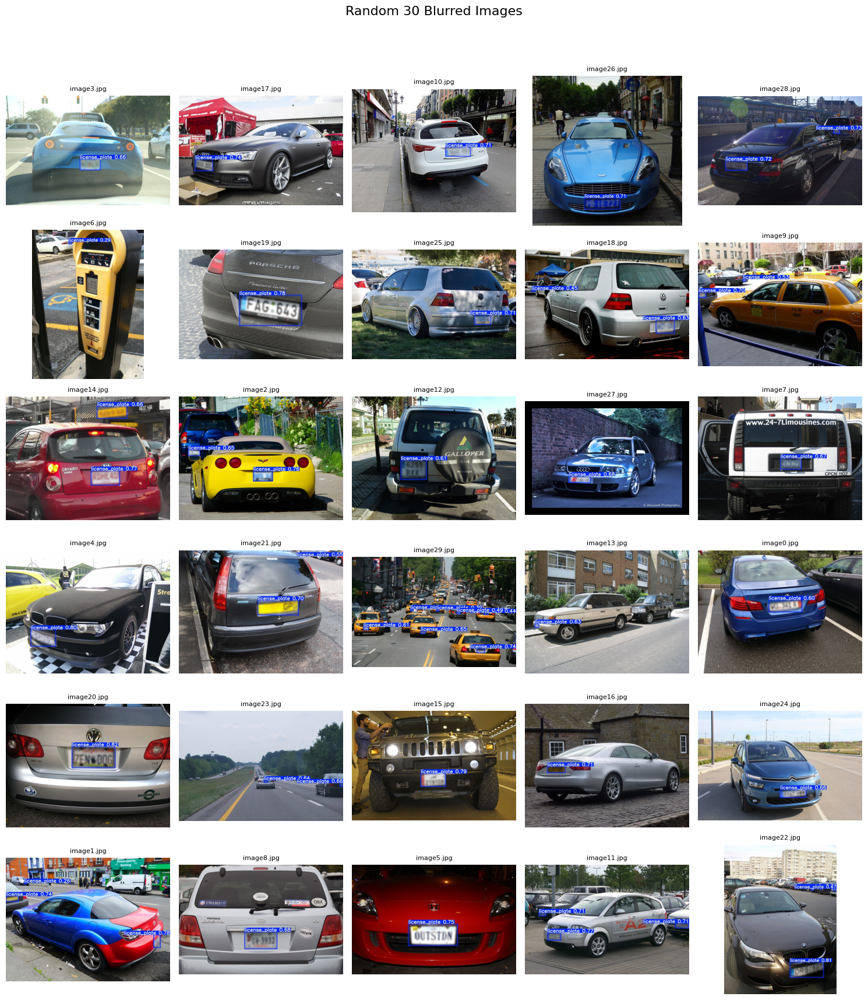

In [14]:
if 'blurred_output_dir' in locals() and os.path.exists(blurred_output_dir):
    # Get a list of blurred image paths
    blurred_image_paths = [os.path.join(blurred_output_dir, f) for f in os.listdir(blurred_output_dir)
                           if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if blurred_image_paths:
        display_num = min(30, len(blurred_image_paths)) # Display up to 30 blurred images
        random_blurred_images = random.sample(blurred_image_paths, display_num)

        display_images(random_blurred_images, title=f"Random {display_num} Blurred Images", ncols=5)
    else:
        print("No blurred images found in the output directory.")
else:
    print("Blurred images output directory not found or blurring step did not run successfully.")

### Quantitative Blur Consistency: Laplacian Variance

Laplacian Variance is a common metric used to measure the amount of blur in an image. A higher variance indicates more detail (less blur), while a lower variance indicates more blur. For anonymization purposes, a very low Laplacian variance in the blurred region is desirable, as it suggests the text is indistinguishable.

Typical values for text to be effectively unreadable often fall below a threshold (e.g., 10-50, depending on image scale and characteristics). We will now inspect the calculated Laplacian variances for the blurred license plate regions.


--- Laplacian Variance Analysis of Blurred Regions ---
Average Laplacian Variance: 4.03
Minimum Laplacian Variance: 2.24
Maximum Laplacian Variance: 6.63


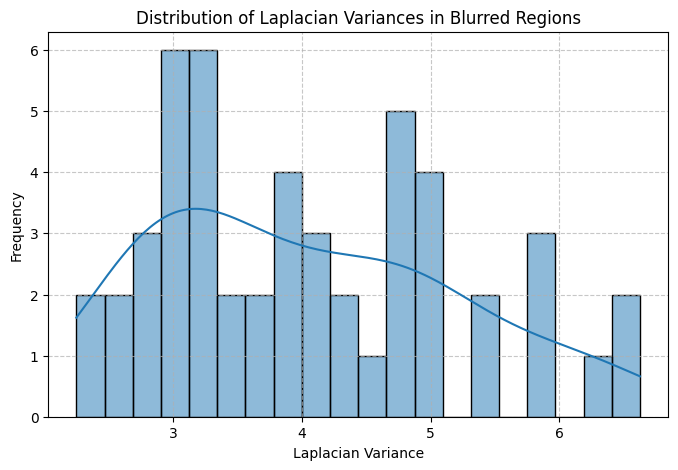

In [15]:
if 'all_laplacian_variances' in locals() and all_laplacian_variances:
    mean_lap_var = np.mean(all_laplacian_variances)
    min_lap_var = np.min(all_laplacian_variances)
    max_lap_var = np.max(all_laplacian_variances)

    print("\n--- Laplacian Variance Analysis of Blurred Regions ---")
    print(f"Average Laplacian Variance: {mean_lap_var:.2f}")
    print(f"Minimum Laplacian Variance: {min_lap_var:.2f}")
    print(f"Maximum Laplacian Variance: {max_lap_var:.2f}")

    # Optional: Plotting distribution of variances
    plt.figure(figsize=(8, 5))
    sns.histplot(all_laplacian_variances, bins=20, kde=True)
    plt.title('Distribution of Laplacian Variances in Blurred Regions')
    plt.xlabel('Laplacian Variance')
    plt.ylabel('Frequency')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

else:
    print("Laplacian Variance data not available. Please ensure the blurring step ran successfully.")


Even though the Laplacian Variance is quite low (indicating high blurring), we see that many of the license plates are still very much readable.

So let's apply Box blur instead of Gaussian blur.

In [16]:
if inference_model and 'results' in locals() and results:
    # Define the output directory for blurred images
    blurred_output_dir = os.path.join(images_base_path, 'blurred_box')
    os.makedirs(blurred_output_dir, exist_ok=True)

    print(f"Saving blurred images to: {blurred_output_dir}")

    # List to store Laplacian variances of blurred regions
    all_laplacian_variances = []

    inference_images_path = '/workspace/runs/detect/predict/'

    # Iterate through each image's results
    for res in results:
        img_path = os.path.join(inference_images_path, res.path)
        img_name = os.path.basename(img_path)

        # Load the original image using OpenCV
        # Convert to RGB if needed, as YOLOv8's results might be in BGR (OpenCV default)
        img = cv2.imread(img_path)
        if img is None:
            print(f"Could not load image {img_path}. Skipping blurring.")
            continue

        # Create a copy to draw on, so the original isn't modified
        blurred_img = img.copy()

        # Iterate through each detected bounding box
        # res.boxes contains normalized coordinates, so we need to convert them to pixel values
        for *xyxy, conf, cls in res.boxes.data.cpu().numpy():
            # Convert normalized xyxy (x1, y1, x2, y2) to integer pixel coordinates
            x1, y1, x2, y2 = map(int, xyxy)

            # Extract the region of interest (ROI) for blurring
            # Ensure coordinates are within image boundaries
            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(blurred_img.shape[1], x2)
            y2 = min(blurred_img.shape[0], y2)

            if x2 > x1 and y2 > y1: # Check if the bounding box is valid
                roi = blurred_img[y1:y2, x1:x2]

                # Apply Box blur to the ROI
                blurred_roi = cv2.blur(roi, (27, 27))

                # Calculate Laplacian Variance for the blurred ROI
                # Convert to grayscale first for Laplacian calculation
                gray_blurred_roi = cv2.cvtColor(blurred_roi, cv2.COLOR_BGR2GRAY)
                lap_var = cv2.Laplacian(gray_blurred_roi, cv2.CV_64F).var()
                all_laplacian_variances.append(lap_var)

                # Place the blurred ROI back into the image
                blurred_img[y1:y2, x1:x2] = blurred_roi

        # Save the blurred image
        output_path = os.path.join(blurred_output_dir, img_name)
        cv2.imwrite(output_path, blurred_img)

    print("All selected images have been processed and blurred. You can find them in the 'blurred' folder.")

    if all_laplacian_variances:
        print(f"\nLaplacian Variances calculated for {len(all_laplacian_variances)} blurred regions.")
        print(f"  Mean Laplacian Variance: {np.mean(all_laplacian_variances):.2f}")
        print(f"  Min Laplacian Variance: {np.min(all_laplacian_variances):.2f}")
        print(f"  Max Laplacian Variance: {np.max(all_laplacian_variances):.2f}")

        # Store for later analysis
        # globals()['all_laplacian_variances'] = all_laplacian_variances # If needed globally
    else:
        print("No regions were blurred to calculate Laplacian Variance.")

else:
    print("No inference results available or model not loaded. Skipping blurring and Laplacian Variance calculation.")

Saving blurred images to: ./data/images/blurred_box
All selected images have been processed and blurred. You can find them in the 'blurred' folder.

Laplacian Variances calculated for 50 blurred regions.
  Mean Laplacian Variance: 3.86
  Min Laplacian Variance: 1.92
  Max Laplacian Variance: 9.34


#### Display Blurred Images (Box Blur)

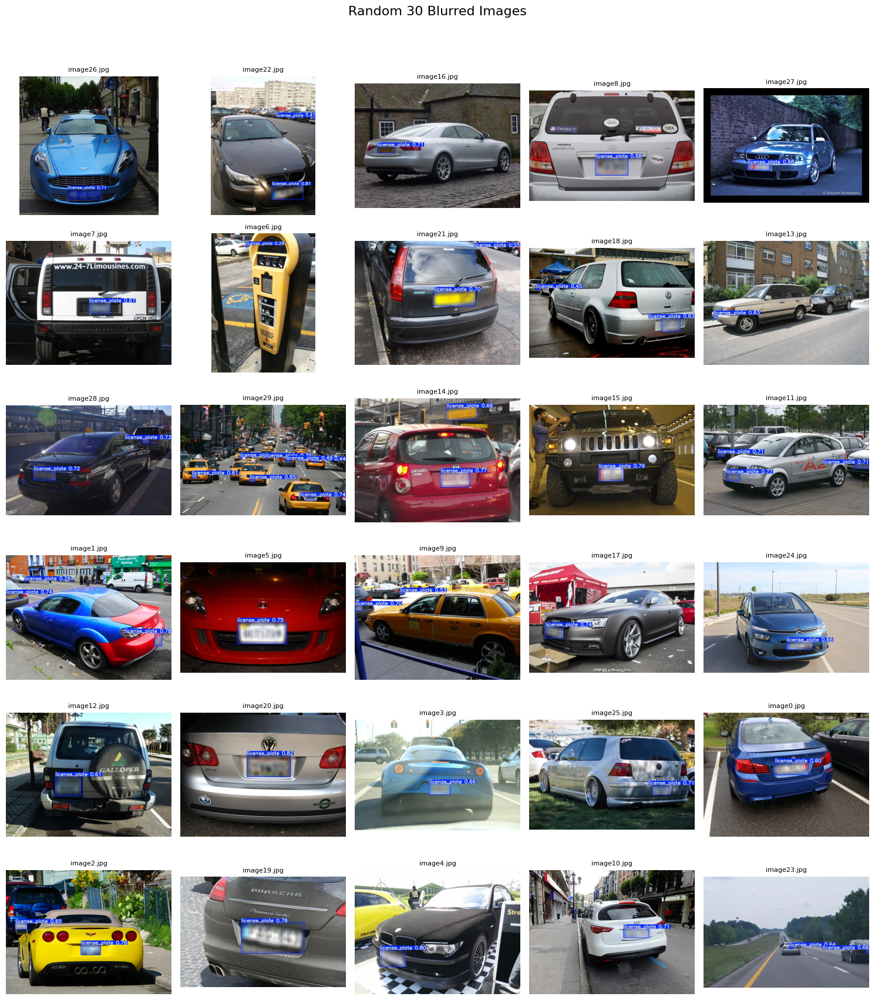

In [17]:
if 'blurred_output_dir' in locals() and os.path.exists(blurred_output_dir):
    # Get a list of blurred image paths
    blurred_image_paths = [os.path.join(blurred_output_dir, f) for f in os.listdir(blurred_output_dir)
                           if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if blurred_image_paths:
        display_num = min(30, len(blurred_image_paths)) # Display up to 30 blurred images
        random_blurred_images = random.sample(blurred_image_paths, display_num)

        display_images(random_blurred_images, title=f"Random {display_num} Blurred Images", ncols=5)
    else:
        print("No blurred images found in the output directory.")
else:
    print("Blurred images output directory not found or blurring step did not run successfully.")

We can see that the license plates are much more severely blurred and unreadable after Box Blur.

#### Laplacian Variances with Box Blur


--- Laplacian Variance Analysis of Blurred Regions ---
Average Laplacian Variance: 3.86
Minimum Laplacian Variance: 1.92
Maximum Laplacian Variance: 9.34


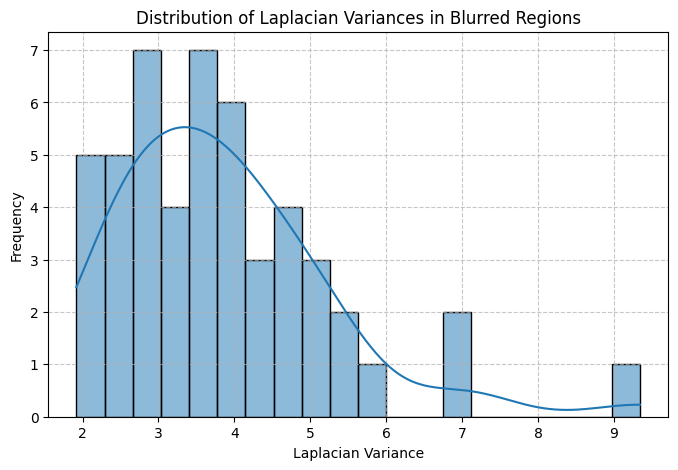

In [18]:
if 'all_laplacian_variances' in locals() and all_laplacian_variances:
    mean_lap_var = np.mean(all_laplacian_variances)
    min_lap_var = np.min(all_laplacian_variances)
    max_lap_var = np.max(all_laplacian_variances)

    print("\n--- Laplacian Variance Analysis of Blurred Regions ---")
    print(f"Average Laplacian Variance: {mean_lap_var:.2f}")
    print(f"Minimum Laplacian Variance: {min_lap_var:.2f}")
    print(f"Maximum Laplacian Variance: {max_lap_var:.2f}")

    # Optional: Plotting distribution of variances
    plt.figure(figsize=(8, 5))
    sns.histplot(all_laplacian_variances, bins=20, kde=True)
    plt.title('Distribution of Laplacian Variances in Blurred Regions')
    plt.xlabel('Laplacian Variance')
    plt.ylabel('Frequency')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

else:
    print("Laplacian Variance data not available. Please ensure the blurring step ran successfully.")